# Punto 8 – Caracterización de los caudales observados
**Trabajo 1 de Hidroclimatología · Cuenca del río Cauca hasta Hidroituango**

Estaciones hidrológicas del IDEAM **sobre el cauce principal del río Cauca**, desde La Balsa hasta Puerto Valdivia.

**Fuente de los caudales:** caudal medio diario (etiqueta `Q_MEDIA_D`) del conjunto de datos abiertos
*Caudales Medios Diarios de los Ríos de Colombia* del IDEAM (datos.gov.co, 2026). El IDEAM publica un archivo CSV
por estación, y este notebook los descarga automáticamente.

**Coordenadas:** Catálogo Nacional de Estaciones del IDEAM (datos.gov.co).

**Metodología**
1. Un mes es válido si tiene datos en al menos el **80 % de los días**.
2. Un año es completo si tiene los **12 meses válidos**.
3. Se usan las estaciones con **15 o más años completos en 1981–2010**, el mismo periodo de la climatología.
4. El área de drenaje de cada estación se delimita con el mismo DEM del punto 2.
5. El caudal medio anual multianual es el promedio de los años completos de 1981–2010.

**Archivos necesarios:** `direccion.tif`, `acumulacion.tif`, `DEM_cuenca.tif` y `cuenca_cauca.gpkg` (punto 2).

**Salidas:**
- `caudales_estaciones.csv` y `areas_drenaje_estaciones.gpkg`, que usa el balance (punto 9).
- Las figuras del punto 8.

## 0. Instalación de librerías
Solo si no las instaló antes. Después de instalar, reinicie el kernel.

In [1]:
%pip install numpy pandas matplotlib geopandas rasterio pyproj shapely requests

Note: you may need to restart the kernel to use updated packages.


## 1. Librerías, parámetros y estaciones

In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import geopandas as gpd
from matplotlib.colors import ListedColormap

pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 30)

# ----------------------------- PARÁMETROS -----------------------------
CRS = "EPSG:3116"
CUENCA = "cuenca_cauca.gpkg"
RIO = "rio_principal.gpkg"
DIRECCION = "direccion.tif"          # "Drainage direction" de r.watershed (punto 2)
ACUMULACION = "acumulacion.tif"      # "Number of cells that drain through each cell" (punto 2)
DEM_CUENCA = "DEM_cuenca.tif"
CARPETA = "caudales"                 # aquí se guardan los CSV descargados del IDEAM
URL_IDEAM = "https://datos.ideam.gov.co/s3-estacionesideam/observaciones/historicos/csv/Q_MEDIA_D/"
PERIODO = (1981, 2010)
MIN_FRACCION_DIAS = 0.80             # mes válido: datos en ≥ 80 % de los días
MIN_ANIOS = 15                       # años completos mínimos en el periodo
RADIO_AJUSTE_KM = 2.0                # radio inicial para llevar la estación a la celda del río en el DEM
RADIO_MAX_KM = 10.0                  # si no hay celda plausible, el radio crece de 2 en 2 km hasta este valor
# ----------------------------------------------------------------------

# Estaciones del IDEAM sobre el río Cauca (Catálogo Nacional de Estaciones, datos.gov.co), de sur a norte
ESTACIONES = pd.DataFrame([
    # codigo,    nombre,             lat,          lon
    ("26027010", "La Balsa",         3.091694444, -76.599083330),
    ("26027050", "La Salvajina",     2.950000000, -76.700000000),
    ("26067010", "Juanchito",        3.451608333, -76.475383330),
    ("26087050", "Mediacanoa",       3.889611111, -76.349972220),
    ("26107070", "La Victoria",      4.516666667, -76.033333330),
    ("26177030", "La Virginia",      4.892500000, -75.882694444),
    ("26167070", "Irra",             5.268305556, -75.664194440),
    ("26187110", "La Pintada",       5.741477800, -75.600563800),
    ("26207030", "Puente Iglesias",  5.829944444, -75.705500000),
    ("26207080", "Bolombolo",        5.970000000, -75.840000000),
    ("26217050", "Cañafisto",        6.417250000, -75.819619444),
    ("26237100", "Olaya",            6.644944444, -75.826166670),
    ("26237050", "Puente Pescadero", 7.088333333, -75.695916670),
    ("26237040", "Puerto Valdivia",  7.286994444, -75.396730556),
], columns=["codigo", "nombre", "lat", "lon"])

# La estación La Pintada queda ANTES de la desembocadura del río Arma: su área de drenaje no debe incluir el Arma.
# Se usa como referencia la estación Quitasueño (26187040) sobre el río Arma.
NO_INCLUIR = {"26187110": [(5.713611111, -75.540277778)]}     # {codigo: [(lat, lon), ...]}

SEG_ANIO = 365.25 * 86400
os.makedirs(CARPETA, exist_ok=True)


def valor_en_punto(arr, info, x, y):
    # Valor de un ráster en la celda que contiene (x, y); NaN si queda fuera o sin dato
    Tr = info["transform"]
    col = int(np.floor((x - Tr.c) / Tr.a)); fila = int(np.floor((y - Tr.f) / Tr.e))
    hh, ww = info["shape"]
    if 0 <= fila < hh and 0 <= col < ww and not np.ma.getmaskarray(arr)[fila, col]:
        return float(arr[fila, col])
    return np.nan


ESTACIONES

,codigo,nombre,lat,lon
0,26027010,La Balsa,3.091694,-76.599083
1,26027050,La Salvajina,2.950000,-76.700000
2,26067010,Juanchito,3.451608,-76.475383
3,26087050,Mediacanoa,3.889611,-76.349972
4,26107070,La Victoria,4.516667,-76.033333
5,26177030,La Virginia,4.892500,-75.882694
6,26167070,Irra,5.268306,-75.664194
7,26187110,La Pintada,5.741478,-75.600564
8,26207030,Puente Iglesias,5.829944,-75.705500
9,26207080,Bolombolo,5.970000,-75.840000


In [3]:
# ----------------------- Funciones de apoyo SIG -----------------------
import rasterio
from rasterio import features
from rasterio.warp import reproject, Resampling
from rasterio.transform import from_origin
from pyproj import Transformer
from shapely.geometry import shape
from shapely.ops import unary_union


def leer_raster(ruta):
    # Devuelve (arreglo enmascarado, info). Si el archivo tiene varias bandas: arreglo (bandas, filas, columnas)
    with rasterio.open(ruta) as src:
        arr = src.read(masked=True).astype("float64")
        info = {"transform": src.transform, "crs": src.crs, "shape": (src.height, src.width),
                "profile": src.profile.copy()}
    return (arr[0] if arr.shape[0] == 1 else arr), info


def guardar_raster(ruta, arr, info, nodata=-9999.0, descripciones=None, dtype="float32"):
    a = np.ma.masked_invalid(np.ma.asarray(arr, dtype="float64"))
    if a.ndim == 2:
        a = a[None]
    perfil = info["profile"].copy()
    perfil.update(driver="GTiff", dtype=dtype, nodata=nodata, count=a.shape[0], compress="lzw")
    with rasterio.open(ruta, "w", **perfil) as dst:
        dst.write(a.filled(nodata).astype(dtype))
        for i, d in enumerate(descripciones or [], start=1):
            dst.set_band_description(i, d)


def coords_celdas(info):
    # Coordenadas (x, y) del centro de cada celda, en el SRC del ráster
    T = info["transform"]
    filas, cols = np.indices(info["shape"])
    return T.a * (cols + 0.5) + T.b * (filas + 0.5) + T.c, T.d * (cols + 0.5) + T.e * (filas + 0.5) + T.f


def a_lonlat(x, y, crs):
    lon, lat = Transformer.from_crs(crs, "EPSG:4326", always_xy=True).transform(np.asarray(x), np.asarray(y))
    return np.asarray(lon), np.asarray(lat)


def de_lonlat(lon, lat, crs):
    x, y = Transformer.from_crs("EPSG:4326", crs, always_xy=True).transform(np.asarray(lon), np.asarray(lat))
    return np.asarray(x), np.asarray(y)


def remuestrear_a_grilla(arr, lon, lat, info, metodo="bilinear"):
    # Lleva un campo en grilla regular lon/lat (2D o 3D con el tiempo primero) a la grilla del DEM
    arr = np.asarray(arr, dtype="float64")
    if lat[0] < lat[-1]:                       # filas de norte a sur
        arr, lat = arr[..., ::-1, :], lat[::-1]
    dx, dy = abs(lon[1] - lon[0]), abs(lat[1] - lat[0])
    src_T = from_origin(lon.min() - dx / 2, lat.max() + dy / 2, dx, dy)
    capas = arr if arr.ndim == 3 else arr[None]
    salida = np.full((capas.shape[0],) + info["shape"], np.nan)
    for k in range(capas.shape[0]):
        reproject(source=np.ascontiguousarray(capas[k]), destination=salida[k], src_transform=src_T,
                  src_crs="EPSG:4326", src_nodata=np.nan, dst_transform=info["transform"], dst_crs=info["crs"],
                  dst_nodata=np.nan, resampling=getattr(Resampling, metodo))
    return salida if arr.ndim == 3 else salida[0]


def mascara_geometria(geom, info):
    # True en las celdas cuyo centro cae dentro de la geometría
    return features.geometry_mask([geom], out_shape=info["shape"], transform=info["transform"], invert=True)


def poligonizar(mascara, info):
    geoms = [shape(g) for g, v in features.shapes(mascara.astype("uint8"), mask=mascara,
                                                    transform=info["transform"]) if v == 1]
    return unary_union(geoms)

In [4]:
def decorar(ax, titulo, ext, cuenca, rio=None):
    # Límite de la cuenca, río, flecha de norte, barra de escala y SRC
    cuenca.boundary.plot(ax=ax, color="k", lw=0.8)
    if rio is not None:
        rio.plot(ax=ax, color="#08306b", lw=1.0)
    ax.annotate("", xy=(0.93, 0.93), xytext=(0.93, 0.84), xycoords="axes fraction",
                arrowprops=dict(arrowstyle="-|>", color="k", lw=1.5))
    ax.text(0.93, 0.945, "N", transform=ax.transAxes, ha="center", fontsize=12, fontweight="bold")
    x0 = ext[0] + 0.06 * (ext[1] - ext[0]); y0 = ext[2] + 0.04 * (ext[3] - ext[2])
    ax.plot([x0, x0 + 50000], [y0, y0], "k-", lw=3)
    ax.text(x0 + 25000, y0 + 0.012 * (ext[3] - ext[2]), "50 km", ha="center", fontsize=8)
    ax.set_title(titulo, fontsize=11)
    ax.text(0.02, 0.005, "MAGNA-SIRGAS / Colombia Bogotá zone (EPSG:3116)", transform=ax.transAxes, fontsize=7,
            bbox=dict(facecolor="white", edgecolor="none", alpha=0.7, pad=1))
    ax.ticklabel_format(style="plain"); ax.tick_params(labelsize=7)
    ax.locator_params(axis="x", nbins=4)
    ax.set_xlim(ext[0], ext[1]); ax.set_ylim(ext[2], ext[3]); ax.set_aspect("equal")


def extension(info):
    T = info["transform"]; h, w = info["shape"]
    return [T.c, T.c + T.a * w, T.f + T.e * h, T.f]


def mapa(arr, info, titulo, etiqueta, cuenca, rio=None, cmap="viridis", archivo=None, vmin=None, vmax=None, ax=None):
    ext = extension(info)
    propio = ax is None
    if propio:
        fig, ax = plt.subplots(figsize=(6, 9))
    im = ax.imshow(arr, extent=ext, cmap=cmap, vmin=vmin, vmax=vmax, interpolation="nearest")
    if propio:
        plt.colorbar(im, ax=ax, shrink=0.6, label=etiqueta)
    decorar(ax, titulo, ext, cuenca, rio)
    if propio:
        fig.tight_layout()
        if archivo:
            fig.savefig(archivo, dpi=200)
        plt.show()
    return im

cuenca = gpd.read_file(CUENCA).to_crs(CRS)
rio = gpd.read_file(RIO).to_crs(CRS) if os.path.exists(RIO) else None

## 2. Descarga del caudal medio diario (IDEAM)
Se descarga un archivo por estación: `00<código>-Q_MEDIA_D.csv`. Si el archivo ya está en la carpeta `caudales`, no
se vuelve a descargar.

Si la descarga falla, por ejemplo por la red de la universidad, abra la dirección que imprime la celda en el
navegador. Guarde el archivo en `caudales` con el mismo nombre y vuelva a correr la celda.

In [5]:
import requests

def archivo(cod):
    return os.path.join(CARPETA, f"00{cod}-Q_MEDIA_D.csv")

for cod, nom in zip(ESTACIONES.codigo, ESTACIONES.nombre):
    ruta = archivo(cod)
    if os.path.exists(ruta) and os.path.getsize(ruta) > 100:
        print(f"{nom:17s} ya descargado")
        continue
    url = URL_IDEAM + os.path.basename(ruta)
    try:
        r = requests.get(url, timeout=120)
        r.raise_for_status()
        with open(ruta, "wb") as f:
            f.write(r.content)
        print(f"{nom:17s} descargado ({len(r.content) / 1e3:,.0f} kB)")
    except Exception as e:
        print(f"{nom:17s} NO se pudo descargar: {e}\n   → descárguelo a mano: {url}")

La Balsa          ya descargado
La Salvajina      ya descargado
Juanchito         ya descargado
Mediacanoa        ya descargado
La Victoria       ya descargado
La Virginia       ya descargado
Irra              ya descargado
La Pintada        ya descargado
Puente Iglesias   ya descargado
Bolombolo         ya descargado
Cañafisto         ya descargado
Olaya             ya descargado
Puente Pescadero  ya descargado
Puerto Valdivia   ya descargado


## 3. Lectura, control de calidad y series mensuales

In [6]:
def leer_ideam(ruta):
    df = pd.read_csv(ruta)
    cols = {c.lower(): c for c in df.columns}
    fecha = pd.to_datetime(df[cols.get("fechaobservacion", df.columns[0])], errors="coerce")
    valor = pd.to_numeric(df[cols.get("valorobservado", df.columns[1])], errors="coerce")
    nivel = df[cols["nivelaprobacion"]] if "nivelaprobacion" in cols else pd.Series("", index=df.index)
    d = pd.DataFrame({"fecha": fecha.dt.normalize(), "Q": valor, "nivel": nivel}).dropna(subset=["fecha", "Q"])
    return d.groupby("fecha").agg(Q=("Q", "mean"), nivel=("nivel", "first"))


def mensual(diario, min_frac=MIN_FRACCION_DIAS):
    g = diario["Q"].resample("MS")
    media, n = g.mean(), g.count()
    return media.where(n >= min_frac * media.index.days_in_month)


diarios, mensuales, control = {}, {}, []
for _, e in ESTACIONES.iterrows():
    if not os.path.exists(archivo(e.codigo)):
        print(f"Falta el archivo de {e.nombre}; se omite"); continue
    d = leer_ideam(archivo(e.codigo))
    diarios[e.codigo] = d
    mensuales[e.codigo] = mensual(d)
    control.append({"codigo": e.codigo, "nombre": e.nombre, "registros diarios": len(d),
                    "desde": d.index.min().date(), "hasta": d.index.max().date(),
                    "ceros": int((d.Q == 0).sum()), "negativos": int((d.Q < 0).sum()),
                    "% Definitivo": 100 * d.nivel.astype(str).str.contains("Definitivo", case=False).mean()})
display(pd.DataFrame(control).round(1))

,codigo,nombre,registros diarios,desde,hasta,ceros,negativos,% Definitivo
0,26027010,La Balsa,24663,1946-01-01,2025-04-10,0,0,0.0
1,26027050,La Salvajina,11842,1946-08-01,1980-12-31,0,0,0.0
2,26067010,Juanchito,24839,1945-10-01,2026-10-10,0,0,0.0
3,26087050,Mediacanoa,8250,1965-06-01,1988-12-31,0,0,0.0
4,26107070,La Victoria,20783,1959-01-01,2026-10-09,0,0,0.0
5,26177030,La Virginia,29187,1946-10-01,2026-10-10,0,0,6.2
6,26167070,Irra,19151,1972-01-01,2026-10-10,0,0,7.6
7,26187110,La Pintada,22407,1965-01-01,2026-10-09,0,0,14.6
8,26207030,Puente Iglesias,16181,1979-01-01,2026-10-09,0,0,20.2
9,26207080,Bolombolo,19981,1971-10-01,2026-10-10,0,0,16.3


## 4. Años completos en 1981–2010 y selección de estaciones

,codigo,nombre,lat,lon,inicio,fin,meses_validos_total,anios_completos_1981_2010,apta
0,26027010,La Balsa,3.091694,-76.599083,1946-01,2025-03,808,22,True
1,26027050,La Salvajina,2.950000,-76.700000,1946-08,1980-12,389,0,False
2,26067010,Juanchito,3.451608,-76.475383,1945-10,2026-09,813,23,True
3,26087050,Mediacanoa,3.889611,-76.349972,1965-06,1988-12,271,7,False
4,26107070,La Victoria,4.516667,-76.033333,1959-01,2026-08,675,24,True
5,26177030,La Virginia,4.892500,-75.882694,1946-10,2026-09,958,29,True
6,26167070,Irra,5.268306,-75.664194,1972-01,2026-09,629,27,True
7,26187110,La Pintada,5.741478,-75.600564,1965-01,2026-09,735,30,True
8,26207030,Puente Iglesias,5.829944,-75.705500,1979-01,2026-09,528,23,True
9,26207080,Bolombolo,5.970000,-75.840000,1971-10,2026-09,653,29,True


Estaciones aptas: ['La Balsa', 'Juanchito', 'La Victoria', 'La Virginia', 'Irra', 'La Pintada', 'Puente Iglesias', 'Bolombolo', 'Cañafisto', 'Puerto Valdivia']
Excluidas: ['La Salvajina (0 años)', 'Mediacanoa (7 años)', 'Olaya (10 años)', 'Puente Pescadero (10 años)']


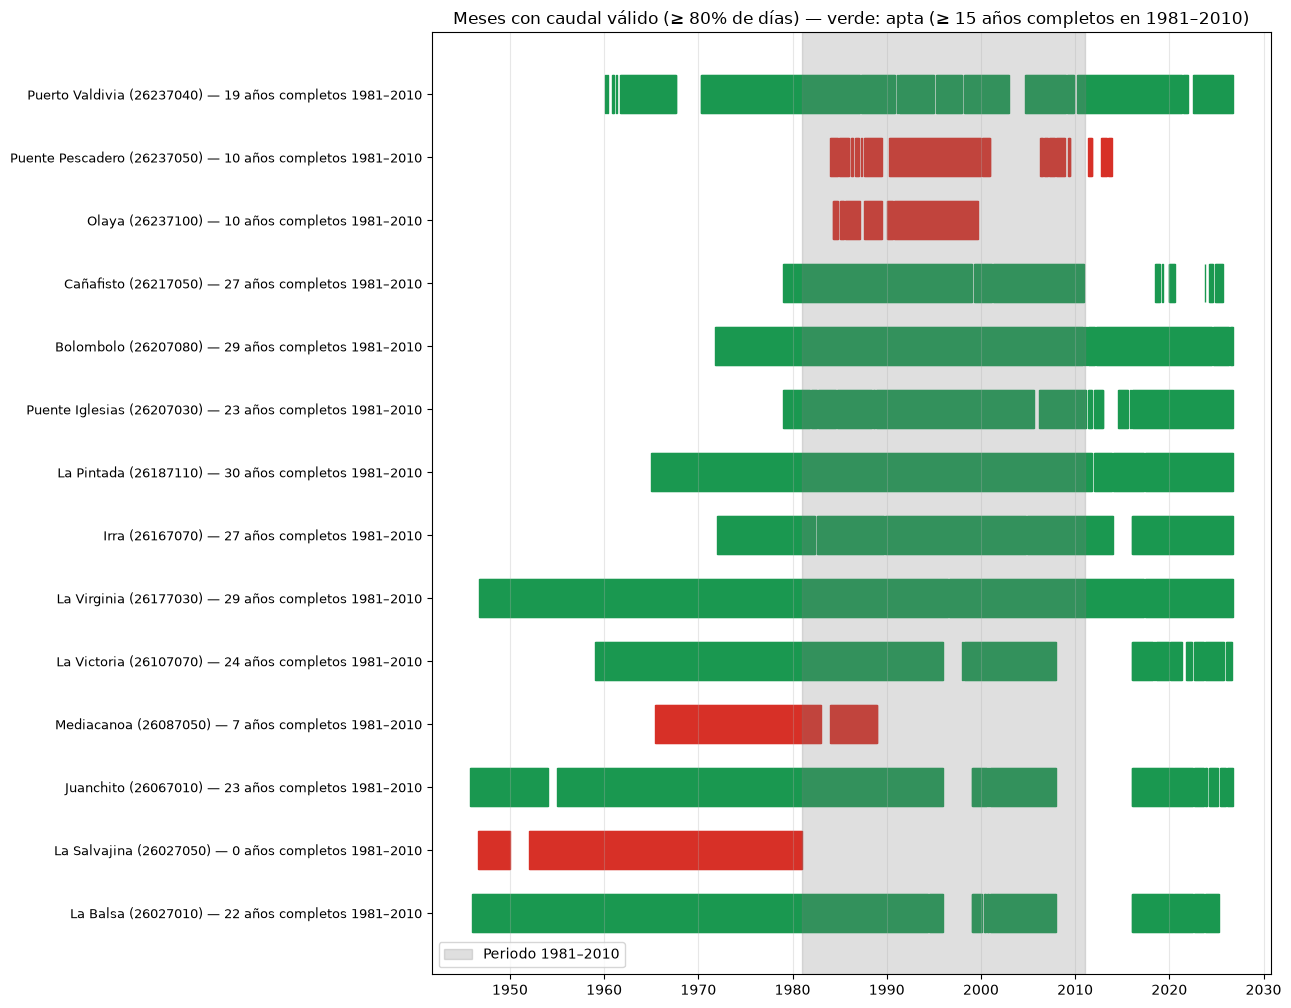

In [7]:
def anios_completos(m, p=PERIODO):
    v = m.dropna()
    v = v[(v.index.year >= p[0]) & (v.index.year <= p[1])]
    c = v.groupby(v.index.year).count()
    return list(c[c == 12].index)


filas = []
for _, e in ESTACIONES.iterrows():
    if e.codigo not in mensuales:
        continue
    m = mensuales[e.codigo]
    ac = anios_completos(m)
    v = m.dropna()
    filas.append({"codigo": e.codigo, "nombre": e.nombre, "lat": e.lat, "lon": e.lon,
                  "inicio": v.index.min().strftime("%Y-%m"), "fin": v.index.max().strftime("%Y-%m"),
                  "meses_validos_total": len(v), "anios_completos_1981_2010": len(ac),
                  "apta": len(ac) >= MIN_ANIOS})
est = pd.DataFrame(filas)
display(est)
print("Estaciones aptas:", list(est.loc[est.apta, "nombre"]))
print("Excluidas:", [f"{n} ({a} años)" for n, a in zip(est.loc[~est.apta, "nombre"], est.loc[~est.apta, "anios_completos_1981_2010"])])

# Gráfica de disponibilidad (meses válidos), con el norte arriba
fig, ax = plt.subplots(figsize=(13, 0.62 * len(est) + 1.5))
for k, (_, e) in enumerate(est.iterrows()):          # sur abajo, norte arriba
    v = mensuales[e.codigo].dropna().index
    inicio = (v.year + (v.month - 1) / 12).to_numpy()
    ax.broken_barh([(t, 1 / 12) for t in inicio], (k - 0.3, 0.6), color="#1a9850" if e.apta else "#d73027")
ax.axvspan(PERIODO[0], PERIODO[1] + 1, color="gray", alpha=0.25, label=f"Periodo {PERIODO[0]}–{PERIODO[1]}")
ax.set_yticks(range(len(est)))
ax.set_yticklabels([f"{e.nombre} ({e.codigo}) — {e.anios_completos_1981_2010} años completos {PERIODO[0]}–{PERIODO[1]}"
                    for _, e in est.iterrows()], fontsize=9)
ax.set_title(f"Meses con caudal válido (≥ {MIN_FRACCION_DIAS:.0%} de días) — verde: apta (≥ {MIN_ANIOS} años completos en "
             f"{PERIODO[0]}–{PERIODO[1]})")
ax.grid(axis="x", alpha=0.3); ax.legend(loc="lower left")
fig.tight_layout(); fig.savefig("fig_disponibilidad_caudales.png", dpi=200)
plt.show()

## 5. Caudal medio anual multianual
Para cada año completo del periodo se calcula el caudal medio anual, que es el promedio de sus 12 meses. El caudal
medio anual multianual es el promedio de esos años.

Los faltantes **no se rellenan**. Para mostrar que el resultado no depende del criterio de faltantes, se recalcula
el caudal exigiendo 70 %, 90 % y 95 % de días por mes.

,nombre,anios_completos_1981_2010,Q_medio_m3s,Q_desv_est_m3s,cambio_70pct_%,cambio_90pct_%,cambio_95pct_%
0,La Balsa,22,178.86,49.22,0.00,-2.94,-2.94
2,Juanchito,23,270.49,65.54,0.00,0.00,0.00
4,La Victoria,24,368.76,106.90,-0.52,0.99,0.99
5,La Virginia,29,538.79,158.23,0.00,0.00,-2.66
6,Irra,27,663.42,190.56,0.00,-2.42,-2.42
7,La Pintada,30,688.88,194.74,0.00,0.00,-1.51
8,Puente Iglesias,23,755.00,230.44,1.67,-3.18,-1.46
9,Bolombolo,29,877.68,238.79,0.00,0.00,-2.45
10,Cañafisto,27,912.32,239.63,0.00,0.00,0.00
13,Puerto Valdivia,19,1122.05,284.06,0.70,-0.75,-0.92


Cambio máximo del caudal medio según el criterio de faltantes: 3.2 %


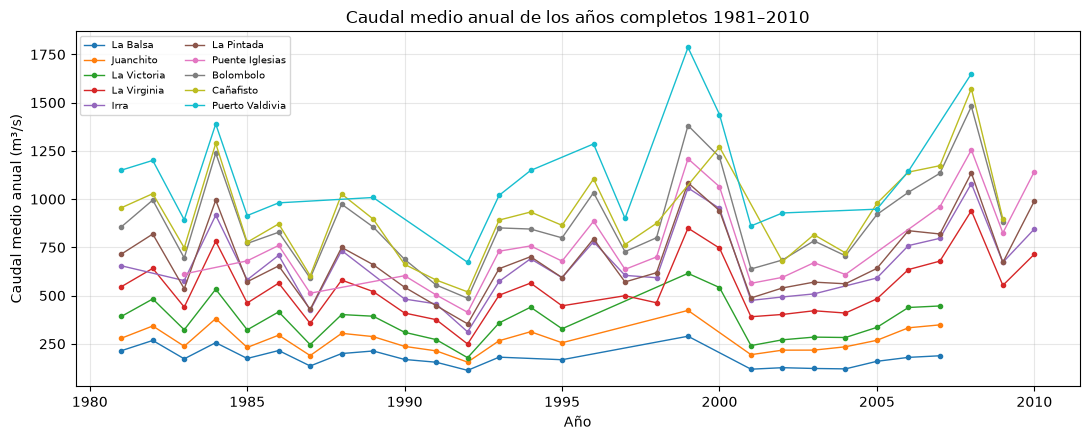

In [8]:
def q_multianual(m):
    v = m.dropna()
    v = v[(v.index.year >= PERIODO[0]) & (v.index.year <= PERIODO[1])]
    anual = v.groupby(v.index.year).agg(["mean", "count"])
    anual = anual[anual["count"] == 12]["mean"]
    return anual.mean(), anual


apt = est[est.apta].copy()
series_anuales = {}
for i, e in apt.iterrows():
    q, anual = q_multianual(mensuales[e.codigo])
    series_anuales[e.codigo] = anual
    apt.loc[i, "Q_medio_m3s"] = q
    apt.loc[i, "Q_desv_est_m3s"] = anual.std()
    for f in (0.7, 0.9, 0.95):
        apt.loc[i, f"Q_{int(f * 100)}pct"] = q_multianual(mensual(diarios[e.codigo], f))[0]
for f in (70, 90, 95):
    apt[f"cambio_{f}pct_%"] = 100 * (apt[f"Q_{f}pct"] / apt["Q_medio_m3s"] - 1)
display(apt[["nombre", "anios_completos_1981_2010", "Q_medio_m3s", "Q_desv_est_m3s",
             "cambio_70pct_%", "cambio_90pct_%", "cambio_95pct_%"]].round(2))
print(f"Cambio máximo del caudal medio según el criterio de faltantes: "
      f"{apt[['cambio_70pct_%', 'cambio_90pct_%', 'cambio_95pct_%']].abs().max().max():.1f} %")

fig, ax = plt.subplots(figsize=(11, 4.5))
for cod, anual in series_anuales.items():
    ax.plot(anual.index, anual.values, marker="o", ms=3, lw=1, label=apt.set_index("codigo").loc[cod, "nombre"])
ax.set(xlabel="Año", ylabel="Caudal medio anual (m³/s)", title="Caudal medio anual de los años completos 1981–2010")
ax.grid(alpha=0.3); ax.legend(fontsize=7, ncol=2)
fig.tight_layout(); fig.savefig("fig_Q_anual_estaciones.png", dpi=200)
plt.show()

## 6. Área de drenaje de cada estación
Se usan los rásters de dirección de flujo y acumulación de `r.watershed` del punto 2. Las coordenadas del catálogo
se llevan a la celda del río en el DEM: la de mayor acumulación a menos de `RADIO_AJUSTE_KM`, con dos controles. Si
ninguna celda los cumple (pasa en el valle geográfico, donde el río del DEM puede quedar a varios km del real), el
radio crece de 2 en 2 km hasta `RADIO_MAX_KM`.
- **Rendimiento plausible:** q = Q/A entre 8 y 150 L/s/km².
- **Puntos excluidos:** el área no puede incluir los puntos de `NO_INCLUIR`. Por ejemplo, La Pintada queda antes de
  la desembocadura del río Arma.

In [9]:
# ===== Dirección de flujo (D8) y acumulación calculadas en Python desde el DEM =====
# Reemplaza las salidas de r.watershed de QGIS. Guarda direccion.tif y acumulacion.tif en esta carpeta.
import glob, heapq, time

DEM_COMPLETO = r""      # ruta de mdt900 (.asc o .tif). Si la deja vacía, se busca automáticamente
CAJA = (-77.6, -74.4, 1.4, 7.8)   # lon mín, lon máx, lat mín, lat máx: la cuenca del Cauca hasta Pto. Valdivia con margen

if not DEM_COMPLETO or not os.path.exists(DEM_COMPLETO):
    cand = []
    for base in [os.getcwd(), os.path.dirname(os.getcwd()), os.path.dirname(os.path.dirname(os.getcwd())),
                 os.path.expanduser(r"~\Desktop"), os.path.expanduser(r"~\Downloads"), r"C:\hidro"]:
        for ext in ("tif", "asc"):
            cand += glob.glob(os.path.join(base, "**", f"mdt900*.{ext}"), recursive=True)
        if cand:
            break
    cand = [c for c in dict.fromkeys(cand) if not c.endswith((".aux.xml", ".ovr"))]
    if not cand:
        raise FileNotFoundError("No encontré mdt900. Escriba su ruta completa en DEM_COMPLETO, p. ej. r'C:\\...\\mdt900.asc'")
    DEM_COMPLETO = sorted(cand, key=lambda c: (not c.lower().endswith(".tif"), len(c)))[0]
print("DEM:", DEM_COMPLETO)

t0 = time.time()
z_full, info_full = leer_raster(DEM_COMPLETO)
Tf = info_full["transform"]
# Ventana del DEM que contiene la caja (en EPSG:3116)
lons = np.r_[np.linspace(CAJA[0], CAJA[1], 50), np.full(50, CAJA[1]), np.linspace(CAJA[1], CAJA[0], 50), np.full(50, CAJA[0])]
lats = np.r_[np.full(50, CAJA[2]), np.linspace(CAJA[2], CAJA[3], 50), np.full(50, CAJA[3]), np.linspace(CAJA[3], CAJA[2], 50)]
xb, yb = de_lonlat(lons, lats, CRS)
c0 = max(int((xb.min() - Tf.c) / Tf.a), 0); c1 = min(int((xb.max() - Tf.c) / Tf.a) + 1, info_full["shape"][1])
r0 = max(int((yb.max() - Tf.f) / Tf.e), 0); r1 = min(int((yb.min() - Tf.f) / Tf.e) + 1, info_full["shape"][0])
z = np.ma.filled(z_full[r0:r1, c0:c1].astype("float64"), np.nan)
z[z < -100] = np.nan
h_, w_ = z.shape
Tw = type(Tf)(Tf.a, Tf.b, Tf.c + c0 * Tf.a + r0 * Tf.b, Tf.d, Tf.e, Tf.f + c0 * Tf.d + r0 * Tf.e)
info_w = {"transform": Tw, "crs": CRS, "shape": (h_, w_), "profile": dict(info_full["profile"])}
info_w["profile"].update(width=w_, height=h_, transform=Tw, crs=CRS)
print(f"Ventana: {h_} × {w_} celdas")

# 1) Relleno de depresiones (priority-flood con un incremento mínimo para que no queden zonas planas)
vec = [(-1, 1), (-1, 0), (-1, -1), (0, -1), (1, -1), (1, 0), (1, 1), (0, 1)]     # códigos GRASS 1..8
nodato = ~np.isfinite(z)
zf = z.copy()
cerrado = nodato.copy()
semilla = np.zeros_like(nodato)
semilla[0, :] = semilla[-1, :] = semilla[:, 0] = semilla[:, -1] = True
for di, dj in vec:                                                                # celdas junto a "sin dato" (mar)
    sh = np.zeros_like(nodato)
    sh[max(-di, 0):h_ + min(-di, 0), max(-dj, 0):w_ + min(-dj, 0)] = nodato[max(di, 0):h_ + min(di, 0), max(dj, 0):w_ + min(dj, 0)]
    semilla |= sh
semilla &= ~nodato
pq = [(zf[i, j], i, j) for i, j in zip(*np.nonzero(semilla))]
heapq.heapify(pq)
cerrado[semilla] = True
while pq:
    zz, i, j = heapq.heappop(pq)
    for di, dj in vec:
        a, b = i + di, j + dj
        if 0 <= a < h_ and 0 <= b < w_ and not cerrado[a, b]:
            cerrado[a, b] = True
            if zf[a, b] <= zz:
                zf[a, b] = zz + 1e-3
            heapq.heappush(pq, (zf[a, b], a, b))

# 2) Dirección D8: hacia el vecino de mayor pendiente
d8 = np.zeros((h_, w_), dtype=np.int16)
mejor = np.zeros((h_, w_))
zpad = np.where(nodato, -1e9, zf)                       # el mar actúa como salida
for k, (di, dj) in enumerate(vec, start=1):
    vecino = np.full((h_, w_), np.inf)
    vecino[max(-di, 0):h_ + min(-di, 0), max(-dj, 0):w_ + min(-dj, 0)] = zpad[max(di, 0):h_ + min(di, 0), max(dj, 0):w_ + min(dj, 0)]
    pend = (zf - vecino) / np.hypot(di, dj)
    m = (pend > mejor) & ~nodato
    mejor[m] = pend[m]; d8[m] = k
sin_dir = (d8 == 0) & ~nodato                            # bordes sin vecino más bajo: salen de la ventana
filas_, cols_ = np.indices((h_, w_))
d8[sin_dir & (filas_ == 0)] = 2; d8[sin_dir & (filas_ == h_ - 1)] = 6
d8[sin_dir & (cols_ == 0)] = 4; d8[sin_dir & (cols_ == w_ - 1)] = 8

# 3) Acumulación: número de celdas que drenan por cada celda (incluida ella misma)
acum = np.where(nodato, 0.0, 1.0).ravel()
dflat = d8.ravel()
orden = np.argsort(np.where(nodato, -np.inf, zf), axis=None)[::-1]
for idx in orden:
    k = dflat[idx]
    if k == 0:
        continue
    i, j = divmod(int(idx), w_)
    a, b = i + vec[k - 1][0], j + vec[k - 1][1]
    if 0 <= a < h_ and 0 <= b < w_:
        acum[a * w_ + b] += acum[idx]
acum = acum.reshape(h_, w_)

guardar_raster("direccion.tif", np.ma.masked_array(d8.astype(float), mask=nodato), info_w)
guardar_raster("acumulacion.tif", np.ma.masked_array(acum, mask=nodato), info_w)
DIRECCION, ACUMULACION = "direccion.tif", "acumulacion.tif"
print(f"Listo en {time.time() - t0:.0f} s: direccion.tif y acumulacion.tif guardados | "
      f"máxima acumulación {acum.max() * abs(Tw.a * Tw.e) / 1e6:,.0f} km²")


DEM: c:\Users\User\Desktop\Unal\Hidrometeorologia\Trabajo 1\Información inicial\CARTOGRAFIA\mdt900.asc
Ventana: 762 × 384 celdas
Listo en 10 s: direccion.tif y acumulacion.tif guardados | máxima acumulación 64,559 km²


In [10]:
dir_r, info_d = leer_raster(DIRECCION)
acc_r, _ = leer_raster(ACUMULACION)
dem_c, info_c = leer_raster(DEM_CUENCA)
d = np.abs(np.ma.filled(dir_r, 0)).astype(int)
acc = np.abs(np.ma.filled(acc_r, 0)).astype(float)
h, w = info_d["shape"]
T = info_d["transform"]
celda_km2 = abs(T.a * T.e) / 1e6

valores = set(np.unique(d[d > 0]).tolist())
if valores <= set(range(1, 9)):
    convencion, despl = "GRASS", {1: (-1, 1), 2: (-1, 0), 3: (-1, -1), 4: (0, -1), 5: (1, -1), 6: (1, 0), 7: (1, 1), 8: (0, 1)}
elif valores <= {1, 2, 4, 8, 16, 32, 64, 128}:
    convencion, despl = "ArcGIS", {1: (0, 1), 2: (1, 1), 4: (1, 0), 8: (1, -1), 16: (0, -1), 32: (-1, -1), 64: (-1, 0), 128: (-1, 1)}
else:
    raise ValueError(f"No se reconoce la convención del ráster de direcciones: {sorted(valores)[:12]}")
idx = np.arange(h * w)
df_ = np.zeros(h * w, int); dc_ = np.zeros(h * w, int)
for k, (a, b) in despl.items():
    s = d.ravel() == k
    df_[s], dc_[s] = a, b
f2, c2 = idx // w + df_, idx % w + dc_
valido = (d.ravel() > 0) & (f2 >= 0) & (f2 < h) & (c2 >= 0) & (c2 < w)
abajo = np.where(valido, f2 * w + c2, idx)
n_saltos = int(np.ceil(np.log2(h * w))) + 1
print(f"Convención de direcciones: {convencion} | grilla {h} × {w} | celda {celda_km2:.3f} km²")


def aguas_arriba(salida):
    nxt = abajo.copy(); nxt[salida] = salida
    for _ in range(n_saltos):
        nxt = nxt[nxt]
    return (nxt == salida).reshape(h, w)


def celda(lat, lon):
    x, y = de_lonlat(lon, lat, CRS)
    x, y = float(np.ravel(x)[0]), float(np.ravel(y)[0])
    return int((y - T.f) / T.e), int((x - T.c) / T.a), x, y


def ajustar(lat, lon, q_obs, excluir=()):
    fila, col, x, y = celda(lat, lon)
    puntos_ex = [celda(la, lo)[:2] for la, lo in excluir]
    radios = np.arange(RADIO_AJUSTE_KM, RADIO_MAX_KM + 1e-9, 2.0)
    for radio_km in radios:
        r = int(np.ceil(radio_km * 1000 / abs(T.a)))
        f0, f1, c0, c1 = max(fila - r, 0), min(fila + r + 1, h), max(col - r, 0), min(col + r + 1, w)
        v = acc[f0:f1, c0:c1].copy()
        ff, cc = np.indices(v.shape)
        v[np.hypot(ff + f0 - fila, cc + c0 - col) > r] = -1
        for k in np.argsort(v, axis=None)[::-1]:
            if v.flat[k] <= 0:
                break
            i, j = np.unravel_index(k, v.shape)
            fi, cj = f0 + i, c0 + j
            q = 1000 * q_obs / (v.flat[k] * celda_km2)
            if not 8 <= q <= 150:
                continue
            m = aguas_arriba(fi * w + cj)
            if any(m[a, b] for a, b in puntos_ex):
                continue
            return fi, cj, m, x, y, "ok" if radio_km == radios[0] else f"ok (radio {radio_km:.0f} km)"
    i, j = np.unravel_index(np.argmax(v), v.shape)
    return f0 + i, c0 + j, aguas_arriba((f0 + i) * w + c0 + j), x, y, "REVISAR"


mascaras, geoms, filas = {}, {}, []
for i, e in apt.iterrows():
    fi, cj, m, x, y, nota = ajustar(e.lat, e.lon, e.Q_medio_m3s, NO_INCLUIR.get(e.codigo, ()))
    xa, ya = T.c + (cj + 0.5) * T.a, T.f + (fi + 0.5) * T.e
    mascaras[e.codigo] = m
    geoms[e.codigo] = poligonizar(m, info_d)
    filas.append({"codigo": e.codigo, "x_ajustada": xa, "y_ajustada": ya, "desplazamiento_m": float(np.hypot(xa - x, ya - y)),
                  "area_km2": m.sum() * celda_km2, "area_por_acumulacion_km2": acc[fi, cj] * celda_km2, "ajuste": nota})
areas = pd.DataFrame(filas)
apt = apt.drop(columns=[c for c in areas.columns if c != "codigo" and c in apt.columns], errors="ignore").merge(areas, on="codigo")
apt["q_L_s_km2"] = 1000 * apt.Q_medio_m3s / apt.area_km2
apt["R_obs_mm"] = apt.Q_medio_m3s * SEG_ANIO / (apt.area_km2 * 1e6) * 1000
apt["dentro_cuenca"] = [np.isfinite(valor_en_punto(dem_c, info_c, x, y)) for x, y in zip(apt.x_ajustada, apt.y_ajustada)]
apt = apt.sort_values("area_km2").reset_index(drop=True)
display(apt[["nombre", "desplazamiento_m", "area_km2", "area_por_acumulacion_km2", "Q_medio_m3s", "q_L_s_km2", "R_obs_mm",
             "ajuste", "dentro_cuenca"]].round(1))

if (abs(apt.area_km2 / apt.area_por_acumulacion_km2 - 1) > 0.02).any():
    print("ADVERTENCIA: el área delimitada no coincide con la acumulación; revise el ráster de direcciones.")
if not apt.Q_medio_m3s.is_monotonic_increasing:
    print("Ojo: el caudal no crece siempre hacia aguas abajo; revise las estaciones marcadas.")
for _, e in apt[~apt.dentro_cuenca].iterrows():
    print(f"{e.nombre}: queda aguas abajo del cierre (Hidroituango); parte de su área sale de los mapas de la cuenca.")
for _, e in apt[apt.ajuste == "REVISAR"].iterrows():
    print(f"REVISAR {e.nombre}: ninguna celda a menos de {RADIO_MAX_KM:.0f} km da un rendimiento plausible "
          f"(quedó con {e.area_km2:,.0f} km² y {e.q_L_s_km2:,.0f} L/s/km²). Revise sus coordenadas.")

Convención de direcciones: GRASS | grilla 762 × 384 | celda 0.868 km²


,nombre,desplazamiento_m,area_km2,area_por_acumulacion_km2,Q_medio_m3s,q_L_s_km2,R_obs_mm,ajuste,dentro_cuenca
0,La Balsa,2248.6,5084.1,5084.1,178.9,35.2,1110.2,ok,True
1,Juanchito,4661.6,5836.9,5836.9,270.5,46.3,1462.4,ok (radio 4 km),True
2,La Victoria,6628.7,15224.5,15224.5,368.8,24.2,764.4,ok (radio 6 km),True
3,La Virginia,2619.2,20948.5,20948.5,538.8,25.7,811.7,ok,True
4,Irra,2977.8,24832.6,24832.6,663.4,26.7,843.1,ok,True
5,La Pintada,951.0,26325.3,26325.3,688.9,26.2,825.8,ok,True
6,Puente Iglesias,2184.3,28750.5,28750.5,755.0,26.3,828.7,ok,True
7,Bolombolo,2604.1,30772.9,30772.9,877.7,28.5,900.1,ok,True
8,Cañafisto,2543.6,32556.4,32556.4,912.3,28.0,884.3,ok,True
9,Puerto Valdivia,2432.5,37395.7,37395.7,1122.0,30.0,946.9,ok,False


Puerto Valdivia: queda aguas abajo del cierre (Hidroituango); parte de su área sale de los mapas de la cuenca.


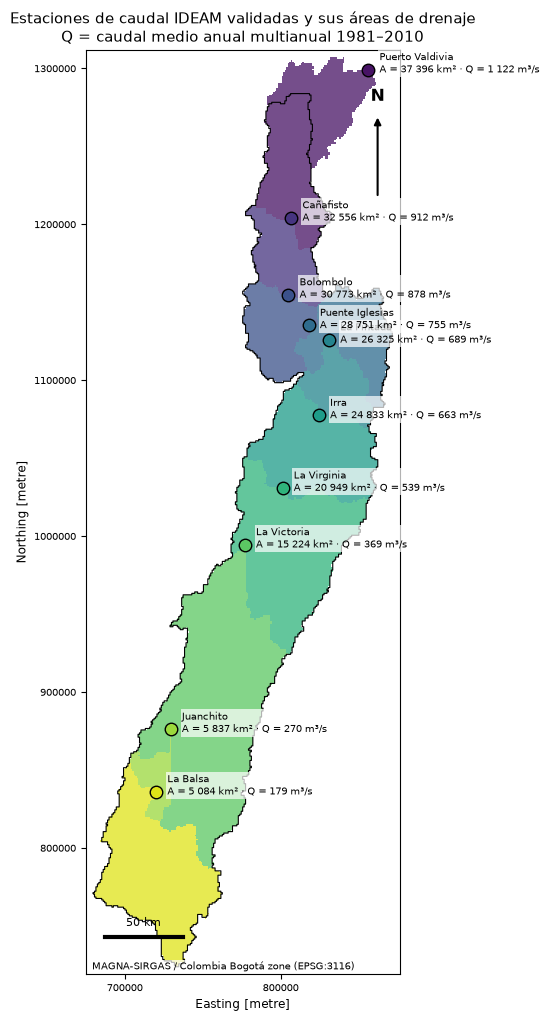

In [11]:
# Mapa de estaciones y áreas de drenaje anidadas
xd, yd = coords_celdas(info_d)
union = np.zeros((h, w), bool)
for m in mascaras.values():
    union |= m
ff, cc = np.nonzero(union)
sl = (slice(max(ff.min() - 5, 0), ff.max() + 6), slice(max(cc.min() - 5, 0), cc.max() + 6))
etiqueta = np.full((h, w), np.nan)
colores = plt.cm.viridis_r(np.linspace(0.05, 0.95, len(apt)))
for k, (_, e) in enumerate(apt.sort_values("area_km2", ascending=False).iterrows()):
    etiqueta[mascaras[e.codigo]] = len(apt) - 1 - k
ext_r = [xd[sl].min() - T.a / 2, xd[sl].max() + T.a / 2, yd[sl].min() - abs(T.e) / 2, yd[sl].max() + abs(T.e) / 2]
fig, ax = plt.subplots(figsize=(8, 12))
ax.imshow(etiqueta[sl], extent=ext_r, cmap=ListedColormap(colores), vmin=-0.5,
          vmax=len(apt) - 0.5, alpha=0.75, interpolation="nearest")
for k, (_, e) in enumerate(apt.iterrows()):
    ax.plot(e.x_ajustada, e.y_ajustada, "o", color=colores[k], mec="k", ms=9, zorder=5)
    ax.annotate(f"{e.nombre}\nA = {e.area_km2:,.0f} km² · Q = {e.Q_medio_m3s:,.0f} m³/s".replace(",", " "),
                (e.x_ajustada, e.y_ajustada), xytext=(8, -2), textcoords="offset points", fontsize=7,
                bbox=dict(facecolor="white", alpha=0.7, edgecolor="none", pad=1), zorder=6)
decorar(ax, f"Estaciones de caudal IDEAM validadas y sus áreas de drenaje\nQ = caudal medio anual multianual "
            f"{PERIODO[0]}–{PERIODO[1]}", ext_r, cuenca, rio)
fig.savefig("fig_estaciones_areas_drenaje.png", dpi=200, bbox_inches="tight")
plt.show()

## 7. Tabla final y archivos para el balance

,codigo,nombre,lat,lon,area_km2,inicio,fin,anios_completos_1981_2010,Q_medio_m3s,q_L_s_km2,R_obs_mm,dentro_cuenca
0,26027010,La Balsa,3.09,-76.60,5084.09,1946-01,2025-03,22,178.86,35.18,1110.20,True
1,26067010,Juanchito,3.45,-76.48,5836.94,1945-10,2026-09,23,270.49,46.34,1462.44,True
2,26107070,La Victoria,4.52,-76.03,15224.49,1959-01,2026-08,24,368.76,24.22,764.37,True
3,26177030,La Virginia,4.89,-75.88,20948.55,1946-10,2026-09,29,538.79,25.72,811.66,True
4,26167070,Irra,5.27,-75.66,24832.60,1972-01,2026-09,27,663.42,26.72,843.08,True
5,26187110,La Pintada,5.74,-75.60,26325.27,1965-01,2026-09,30,688.88,26.17,825.80,True
6,26207030,Puente Iglesias,5.83,-75.71,28750.52,1979-01,2026-09,23,755.00,26.26,828.71,True
7,26207080,Bolombolo,5.97,-75.84,30772.87,1971-10,2026-09,29,877.68,28.52,900.07,True
8,26217050,Cañafisto,6.42,-75.82,32556.43,1979-01,2025-08,27,912.32,28.02,884.33,True
9,26237040,Puerto Valdivia,7.29,-75.40,37395.65,1960-02,2026-09,19,1122.05,30.00,946.88,False


Guardados: caudales_estaciones.csv y areas_drenaje_estaciones.gpkg


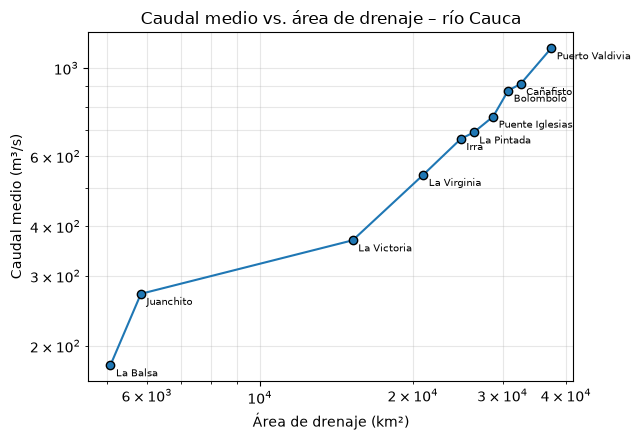

In [12]:
tabla8 = apt[["codigo", "nombre", "lat", "lon", "area_km2", "inicio", "fin", "anios_completos_1981_2010",
              "Q_medio_m3s", "q_L_s_km2", "R_obs_mm", "dentro_cuenca"]].copy()
display(tabla8.round(2))

salida = apt.copy()
salida["Q_usado"] = f"{PERIODO[0]}-{PERIODO[1]} (años completos)"
salida.to_csv("caudales_estaciones.csv", index=False, encoding="utf-8-sig")
sub = gpd.GeoDataFrame(apt[["codigo", "nombre", "area_km2", "Q_medio_m3s"]].copy(),
                       geometry=[geoms[c] for c in apt.codigo], crs=CRS)
sub.to_file("areas_drenaje_estaciones.gpkg", driver="GPKG")
print("Guardados: caudales_estaciones.csv y areas_drenaje_estaciones.gpkg")

fig, ax = plt.subplots(figsize=(6.5, 4.5))
ax.loglog(apt.area_km2, apt.Q_medio_m3s, "o-", mec="k")
for _, e in apt.iterrows():
    ax.annotate(e.nombre, (e.area_km2, e.Q_medio_m3s), fontsize=7, xytext=(4, -8), textcoords="offset points")
ax.set(xlabel="Área de drenaje (km²)", ylabel="Caudal medio (m³/s)", title="Caudal medio vs. área de drenaje – río Cauca")
ax.grid(alpha=0.3, which="both")
fig.tight_layout(); fig.savefig("fig_Q_vs_area.png", dpi=200)
plt.show()

### Para el informe
- **Metodología:**
  - caudal medio diario del IDEAM (datos abiertos);
  - mes válido con ≥ 80 % de días; año completo con 12 meses;
  - estaciones con ≥ 15 años completos en 1981–2010;
  - áreas delimitadas con el mismo DEM;
  - caudal medio anual multianual como promedio de los años completos.
- **Decisiones:**
  - **Periodo 1981–2010:** es el de la precipitación y la temperatura, y además es anterior al llenado de
    Hidroituango (2019).
  - **Faltantes sin rellenar:** reporte cuántos ceros o negativos hay (sección 3) y cuánto cambian las medias según el
    criterio de faltantes (sección 5).
  - **La Pintada antes del río Arma:** compare el aumento de caudal entre Irra y La Pintada con el aporte del Arma.
  - **Estaciones excluidas:** las que tienen menos de 15 años completos (sección 4).
- **Puerto Valdivia** queda aguas abajo de la presa de Hidroituango, es decir, fuera de la cuenca hasta el cierre.
  Se reporta, pero en el balance solo se puede usar si su área queda casi toda cubierta por los mapas.